 梯度消失：训练无进展、仅仅顶部层训练的好

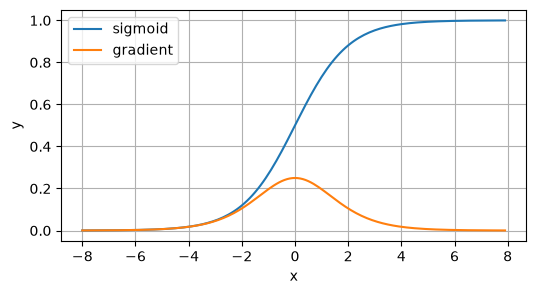

In [1]:
import torch

x=torch.arange(-8.0,8.0,0.1,requires_grad=True)
y=torch.sigmoid(x)
y.backward(torch.ones_like(x))

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.plot(x.detach().numpy(), y.detach().numpy(), label='sigmoid')
plt.plot(x.detach().numpy(), x.grad.numpy(), label='gradient')
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

sigmoid函数:f'(x)=f(x)(1-f(x))，因为f(x)本身就小于1，不断相乘就趋向于0

梯度爆炸：对学习率敏感

In [4]:
M=torch.normal(0,1,size=(4,4))
print('一个矩阵\n',M)
for i in range(100):
    M=torch.mm(M,torch.normal(0,1,size=(4,4)))
print('乘以100个矩阵后\n',M)

一个矩阵
 tensor([[ 1.5894,  0.0270,  1.2321,  0.5229],
        [-1.3680, -0.1705, -0.1671,  0.0222],
        [ 0.0077, -0.2592, -0.2443, -0.9213],
        [ 0.2167, -1.8392,  0.1151,  0.2503]])
乘以100个矩阵后
 tensor([[ 4.9293e+24,  1.3326e+25,  9.4648e+24,  1.8641e+25],
        [-2.2969e+24, -6.2094e+24, -4.4102e+24, -8.6859e+24],
        [ 2.2350e+24,  6.0420e+24,  4.2913e+24,  8.4517e+24],
        [ 9.5250e+24,  2.5750e+25,  1.8289e+25,  3.6019e+25]])


小结：常发生在深度模型中，因为其会对n个数相乘